# Questão 2 — Classificadores na Spambase

Compara 5 classificadores (bayesiano gaussiano, bayesiano k-vizinhos, bayesiano Parzen, regressão logística e voto
majoritário) em duas versões da Spambase:

- **v1:** rótulo original (spam / não-spam);
- **v2:** cluster de objetos do double k-means da Questão 1 (K\* = 2).

Este notebook só chama os scripts da pasta `questao-02/` e mostra os resultados. A implementação e as decisões
estão em `classificadores.py`, `comum.py` e no `README.md` da pasta.

**Tempo de execução.** Com `RODAR_CV = False` e `RODAR_CURVAS = False` o notebook usa os resultados já salvos em
`questao-02/output/` e roda em segundos. Com `True`, refaz tudo: a validação cruzada leva ~10 min com 10 núcleos
(mais no Colab, que tem 2) e as curvas, alguns minutos.

In [1]:
RODAR_CV = False       # True: refaz as 300 avaliações de cada classificador nas duas versões (item a)
RODAR_CURVAS = False   # True: refaz as curvas de aprendizagem (item d)

## Configuração

In [2]:
# Localiza a pasta questao-02. No Colab, baixa o repositório do GitHub na primeira execução.
import os
import subprocess
import sys
from pathlib import Path

REPOSITORIO = "https://github.com/ergdln/IN1102-AM.git"
BRANCH = "questao-02-pipeline"

if "google.colab" in sys.modules and not Path("IN1102-AM").exists():
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPOSITORIO], check=True)

candidatas = [Path.cwd(), Path.cwd() / "questao-02", Path("IN1102-AM") / "questao-02"]
PASTA = next(p.resolve() for p in candidatas if (p / "comum.py").exists())
os.chdir(PASTA)
sys.path.insert(0, str(PASTA))
print("Pasta da questão 2 encontrada:", f"{PASTA.parent.name}/{PASTA.name}")

Pasta da questão 2 encontrada: IN1102-AM/questao-02


In [3]:
import warnings
import pandas as pd
from IPython.display import Image, Markdown, display

import analisar
import comum
import curva_aprendizagem
import executar_cv
from classificadores import NOMES

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 4)

## Dados

4601 e-mails × 57 atributos numéricos: 48 frequências (%) de palavras, 6 frequências (%) de caracteres e 3
estatísticas de sequências de letras maiúsculas. Em ambas as versões a classe positiva (1) é a minoritária; precisão,
cobertura e F-measure são calculadas para ela.

In [4]:
X, ys = comum.carregar_dados()
print("X:", X.shape)
for versao, y in ys.items():
    n1 = y.sum()
    print(f"{versao}: classe 0 = {len(y) - n1}, classe 1 (positiva) = {n1} ({n1 / len(y):.2%})")

X: (4601, 57)
v1: classe 0 = 2788, classe 1 (positiva) = 1813 (39.40%)
v2: classe 0 = 4567, classe 1 (positiva) = 34 (0.74%)


Os 30 × 10 folds estratificados são sorteados uma vez por versão e salvos em `splits/`; todos os classificadores
usam os mesmos 300 splits. Conferência: cada e-mail é teste exatamente uma vez por repetição e a proporção de
positivos se mantém em cada fold de teste.

In [5]:
for versao, y in ys.items():
    splits = comum.carregar_splits(y, versao)
    positivos = [y[teste].sum() for _, _, _, teste in splits]
    print(f"{versao}: {len(splits)} splits | treino {len(splits[0][2])} e-mails, teste {len(splits[0][3])} | "
          f"positivos por fold de teste: {min(positivos)} a {max(positivos)}")

v1: 300 splits | treino 4140 e-mails, teste 461 | positivos por fold de teste: 181 a 182
v2: 300 splits | treino 4140 e-mails, teste 461 | positivos por fold de teste: 3 a 4


## (a) Validação cruzada estratificada 30 × 10-folds (aninhada)

Em cada um dos 300 splits: hiper-parâmetros escolhidos por CV estratificada de 5 folds nos 9 folds de treino
(maior F-measure média), re-treino com os 9 folds e avaliação no fold de teste. O voto majoritário combina as
previsões dos 4 classificadores no mesmo fold de teste.

In [6]:
if RODAR_CV:
    for arquivo in Path("output").glob("*_cv_*.csv"):
        arquivo.unlink()   # apaga os resultados salvos para refazer do zero
    for versao in comum.VERSOES:
        executar_cv.executar(versao, comum.N_REPETICOES)

resultados = {v: pd.read_csv(f"output/resultados_cv_{v}.csv") for v in comum.VERSOES}
for versao, res in resultados.items():
    medias = res.groupby("classificador", sort=False)[list(comum.METRICAS)].mean()
    medias.index = medias.index.map(NOMES)
    medias.columns = [comum.NOMES_METRICAS[m] for m in medias.columns]
    display(Markdown(f"**{versao}**: média das {len(res) // len(NOMES)} avaliações"), medias.round(4))

**v1**: média das 300 avaliações

,Taxa de erro,Precisão,Cobertura,F-measure
classificador,,,,
Bayesiano gaussiano,0.1708,0.7128,0.9506,0.8145
Bayesiano k-vizinhos,0.0860,0.9132,0.8649,0.8879
Bayesiano Parzen,0.0798,0.9146,0.8802,0.8968
Regressão logística,0.0725,0.9231,0.8905,0.9063
Voto majoritário,0.0641,0.9201,0.9175,0.9186


**v2**: média das 300 avaliações

,Taxa de erro,Precisão,Cobertura,F-measure
classificador,,,,
Bayesiano gaussiano,0.0036,0.7910,0.7486,0.7444
Bayesiano k-vizinhos,0.0008,0.9666,0.9378,0.9426
Bayesiano Parzen,0.0003,0.9748,0.9875,0.9772
Regressão logística,0.0006,0.9464,0.9906,0.9632
Voto majoritário,0.0002,0.9862,0.9906,0.9855


## (b) e (c) Intervalos de confiança, Friedman e Nemenyi

IC de 95% com a correção de Nadeau & Bengio, porque as 300 avaliações não são independentes. Friedman sobre os
postos dos 5 classificadores em cada avaliação e, se H0 é rejeitada, Nemenyi (CD = 0,352 para k = 5 e N = 300).

In [7]:
analisar.main()
display(Markdown(Path("output/resultados.md").read_text(encoding="utf-8")
                 .replace("](cd_", "](output/cd_")))

[v1] tabelas e gráfico gerados


[v2] tabelas e gráfico gerados
Resumo em output/resultados.md


# Resultados da Questão 2

Gerado por `analisar.py` a partir de `resultados_cv_<versao>.csv` (validação cruzada estratificada 30 × 10-folds, 300 avaliações por classificador). Precisão, cobertura e F-measure são da classe positiva (minoritária): spam na v1, o cluster de 34 e-mails na v2.

## Versão 1 — rótulo original (spam / não-spam)

### b) Estimativa pontual e IC 95% (correção de Nadeau & Bengio)

| Classificador | Taxa de erro | Precisão | Cobertura | F-measure |
|---|---|---|---|---|
| Bayesiano gaussiano | 0.1708 [0.1607, 0.1808] | 0.7128 [0.6998, 0.7257] | 0.9506 [0.9406, 0.9606] | 0.8145 [0.8050, 0.8240] |
| Bayesiano k-vizinhos | 0.0860 [0.0773, 0.0946] | 0.9132 [0.8968, 0.9296] | 0.8649 [0.8456, 0.8842] | 0.8879 [0.8764, 0.8995] |
| Bayesiano Parzen | 0.0798 [0.0718, 0.0877] | 0.9146 [0.9012, 0.9280] | 0.8802 [0.8647, 0.8957] | 0.8968 [0.8864, 0.9073] |
| Regressão logística | 0.0725 [0.0649, 0.0801] | 0.9231 [0.9100, 0.9362] | 0.8905 [0.8761, 0.9050] | 0.9063 [0.8964, 0.9162] |
| Voto majoritário | 0.0641 [0.0564, 0.0717] | 0.9201 [0.9071, 0.9331] | 0.9175 [0.9046, 0.9304] | 0.9186 [0.9089, 0.9283] |

### c) Friedman e Nemenyi

| Métrica | χ² | p-valor | Rejeita H0? | CD | Postos médios (1 = melhor) |
|---|---|---|---|---|---|
| Taxa de erro | 957.2 | 6.68e-206 | sim | 0.352 | Voto majoritário 1.26, Regressão logística 2.25, Bayesiano Parzen 2.97, Bayesiano k-vizinhos 3.52, Bayesiano gaussiano 5.00 |
| Precisão | 636.8 | 1.71e-136 | sim | 0.352 | Regressão logística 2.17, Voto majoritário 2.29, Bayesiano Parzen 2.71, Bayesiano k-vizinhos 2.83, Bayesiano gaussiano 5.00 |
| Cobertura | 984.1 | 9.73e-212 | sim | 0.352 | Bayesiano gaussiano 1.04, Voto majoritário 2.06, Regressão logística 3.44, Bayesiano Parzen 3.94, Bayesiano k-vizinhos 4.51 |
| F-measure | 975.5 | 7.37e-210 | sim | 0.352 | Voto majoritário 1.19, Regressão logística 2.28, Bayesiano Parzen 2.96, Bayesiano k-vizinhos 3.57, Bayesiano gaussiano 5.00 |

Pares **sem** diferença significativa (Nemenyi, α = 0,05):

- Taxa de erro: nenhum (todos diferem)
- Precisão: Bayesiano k-vizinhos × Bayesiano Parzen; Regressão logística × Voto majoritário
- Cobertura: nenhum (todos diferem)
- F-measure: nenhum (todos diferem)

![Diagrama de diferença crítica](output/cd_v1.png)

### Hiper-parâmetros escolhidos na CV interna (mais frequentes)

| Classificador | Configuração | Vezes escolhida (de 300) |
|---|---|---|
| Bayesiano gaussiano | reg=1e-05 | 117 |
| Bayesiano gaussiano | reg=0.0001 | 101 |
| Bayesiano gaussiano | reg=1e-06 | 82 |
| Bayesiano k-vizinhos | metrica=cityblock, k=1 | 120 |
| Bayesiano k-vizinhos | metrica=cityblock, k=5 | 106 |
| Bayesiano k-vizinhos | metrica=euclidean, k=1 | 32 |
| Bayesiano k-vizinhos | metrica=cityblock, k=7 | 29 |
| Bayesiano Parzen | h=0.5 | 173 |
| Bayesiano Parzen | h=0.6 | 123 |
| Bayesiano Parzen | h=0.7 | 4 |
| Regressão logística | C=30.0 | 107 |
| Regressão logística | C=100.0 | 63 |
| Regressão logística | C=10.0 | 61 |
| Regressão logística | C=1000.0 | 41 |

## Versão 2 — clusters do double k-means (K* = 2)

### b) Estimativa pontual e IC 95% (correção de Nadeau & Bengio)

| Classificador | Taxa de erro | Precisão | Cobertura | F-measure |
|---|---|---|---|---|
| Bayesiano gaussiano | 0.0036 [0.0019, 0.0054] | 0.7910 [0.6475, 0.9345] | 0.7486 [0.5949, 0.9023] | 0.7444 [0.6203, 0.8684] |
| Bayesiano k-vizinhos | 0.0008 [0.0000, 0.0016] | 0.9666 [0.9105, 1.0000] | 0.9378 [0.8463, 1.0000] | 0.9426 [0.8808, 1.0000] |
| Bayesiano Parzen | 0.0003 [0.0000, 0.0009] | 0.9748 [0.9260, 1.0000] | 0.9875 [0.9348, 1.0000] | 0.9772 [0.9324, 1.0000] |
| Regressão logística | 0.0006 [0.0000, 0.0013] | 0.9464 [0.8795, 1.0000] | 0.9906 [0.9417, 1.0000] | 0.9632 [0.9126, 1.0000] |
| Voto majoritário | 0.0002 [0.0000, 0.0007] | 0.9862 [0.9494, 1.0000] | 0.9906 [0.9417, 1.0000] | 0.9855 [0.9455, 1.0000] |

### c) Friedman e Nemenyi

| Métrica | χ² | p-valor | Rejeita H0? | CD | Postos médios (1 = melhor) |
|---|---|---|---|---|---|
| Taxa de erro | 617.8 | 2.17e-132 | sim | 0.352 | Voto majoritário 2.35, Bayesiano Parzen 2.48, Regressão logística 2.74, Bayesiano k-vizinhos 2.94, Bayesiano gaussiano 4.49 |
| Precisão | 349.5 | 2.21e-74 | sim | 0.352 | Voto majoritário 2.59, Bayesiano Parzen 2.69, Bayesiano k-vizinhos 2.78, Regressão logística 2.98, Bayesiano gaussiano 3.96 |
| Cobertura | 567.4 | 1.80e-121 | sim | 0.352 | Regressão logística 2.60, Voto majoritário 2.60, Bayesiano Parzen 2.62, Bayesiano k-vizinhos 3.02, Bayesiano gaussiano 4.16 |
| F-measure | 641.6 | 1.57e-137 | sim | 0.352 | Voto majoritário 2.35, Bayesiano Parzen 2.46, Regressão logística 2.71, Bayesiano k-vizinhos 2.96, Bayesiano gaussiano 4.53 |

Pares **sem** diferença significativa (Nemenyi, α = 0,05):

- Taxa de erro: Bayesiano k-vizinhos × Regressão logística; Bayesiano Parzen × Regressão logística; Bayesiano Parzen × Voto majoritário
- Precisão: Bayesiano k-vizinhos × Bayesiano Parzen; Bayesiano k-vizinhos × Regressão logística; Bayesiano k-vizinhos × Voto majoritário; Bayesiano Parzen × Regressão logística; Bayesiano Parzen × Voto majoritário
- Cobertura: Bayesiano Parzen × Regressão logística; Bayesiano Parzen × Voto majoritário; Regressão logística × Voto majoritário
- F-measure: Bayesiano k-vizinhos × Regressão logística; Bayesiano Parzen × Regressão logística; Bayesiano Parzen × Voto majoritário

![Diagrama de diferença crítica](output/cd_v2.png)

### Hiper-parâmetros escolhidos na CV interna (mais frequentes)

| Classificador | Configuração | Vezes escolhida (de 300) |
|---|---|---|
| Bayesiano gaussiano | reg=1e-06 | 300 |
| Bayesiano k-vizinhos | metrica=euclidean, k=1 | 173 |
| Bayesiano k-vizinhos | metrica=euclidean, k=11 | 36 |
| Bayesiano k-vizinhos | metrica=cityblock, k=1 | 35 |
| Bayesiano k-vizinhos | metrica=euclidean, k=15 | 25 |
| Bayesiano Parzen | h=2.0 | 179 |
| Bayesiano Parzen | h=3.0 | 104 |
| Bayesiano Parzen | h=1.0 | 11 |
| Bayesiano Parzen | h=1.5 | 4 |
| Regressão logística | C=0.1 | 147 |
| Regressão logística | C=0.3 | 110 |
| Regressão logística | C=1.0 | 32 |
| Regressão logística | C=0.03 | 5 |


### Diagramas de diferença crítica

**v1**

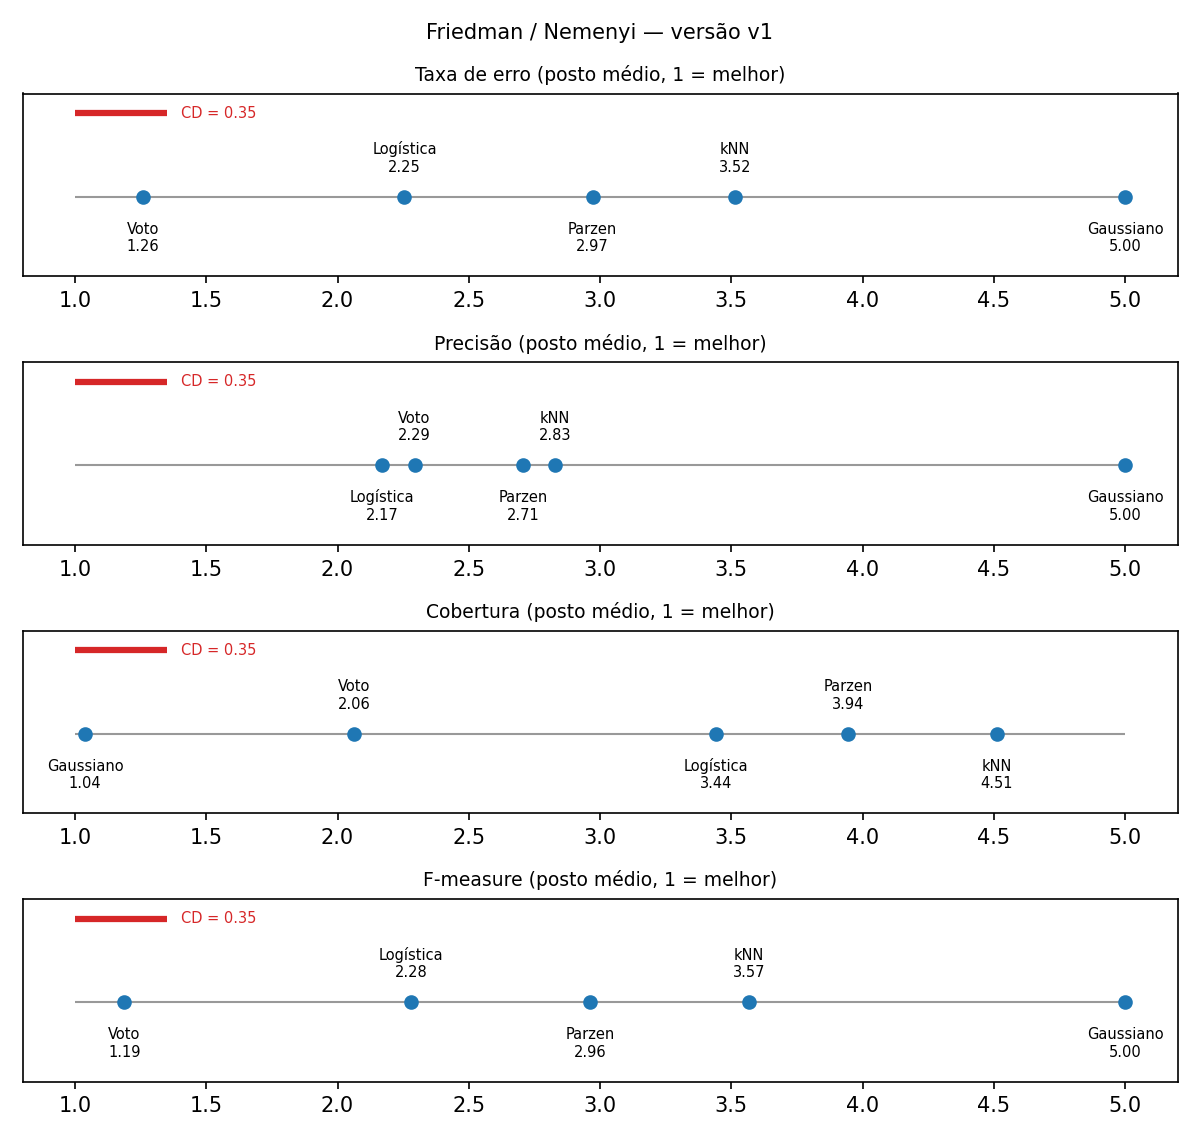

**v2**

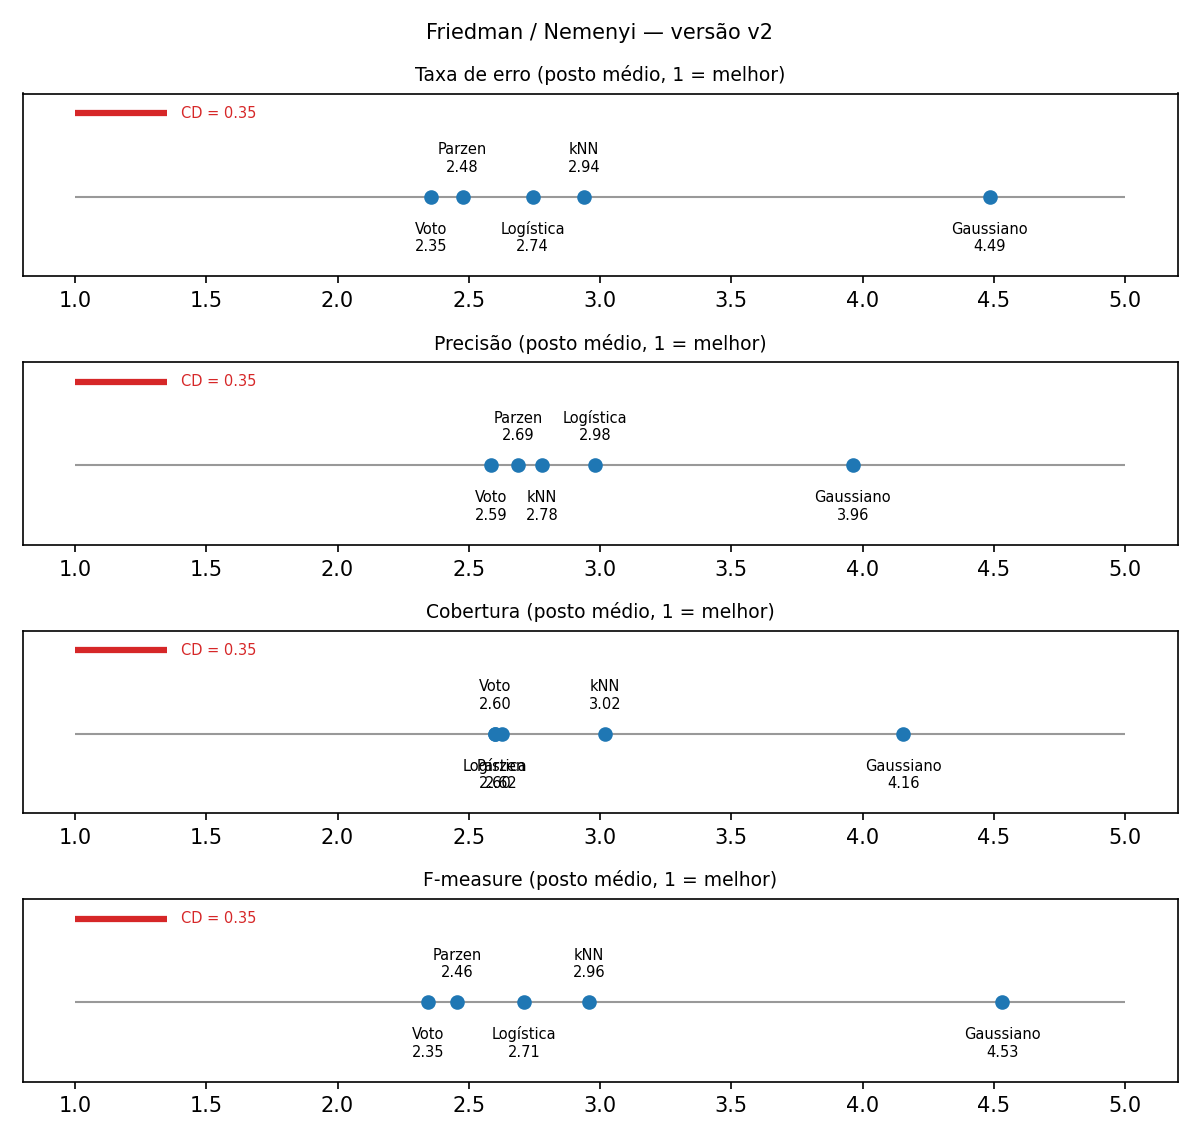

In [8]:
for versao in comum.VERSOES:
    display(Markdown(f"**{versao}**"), Image(f"output/cd_{versao}.png", width=700))

## (d) Curvas de aprendizagem (F-measure)

Treino de 5% a 95% (passo de 5%), divisão estratificada, 5 sorteios por proporção; F-measure no treino e no teste.
Hiper-parâmetros fixos na configuração mais escolhida no item (a).

**v1**

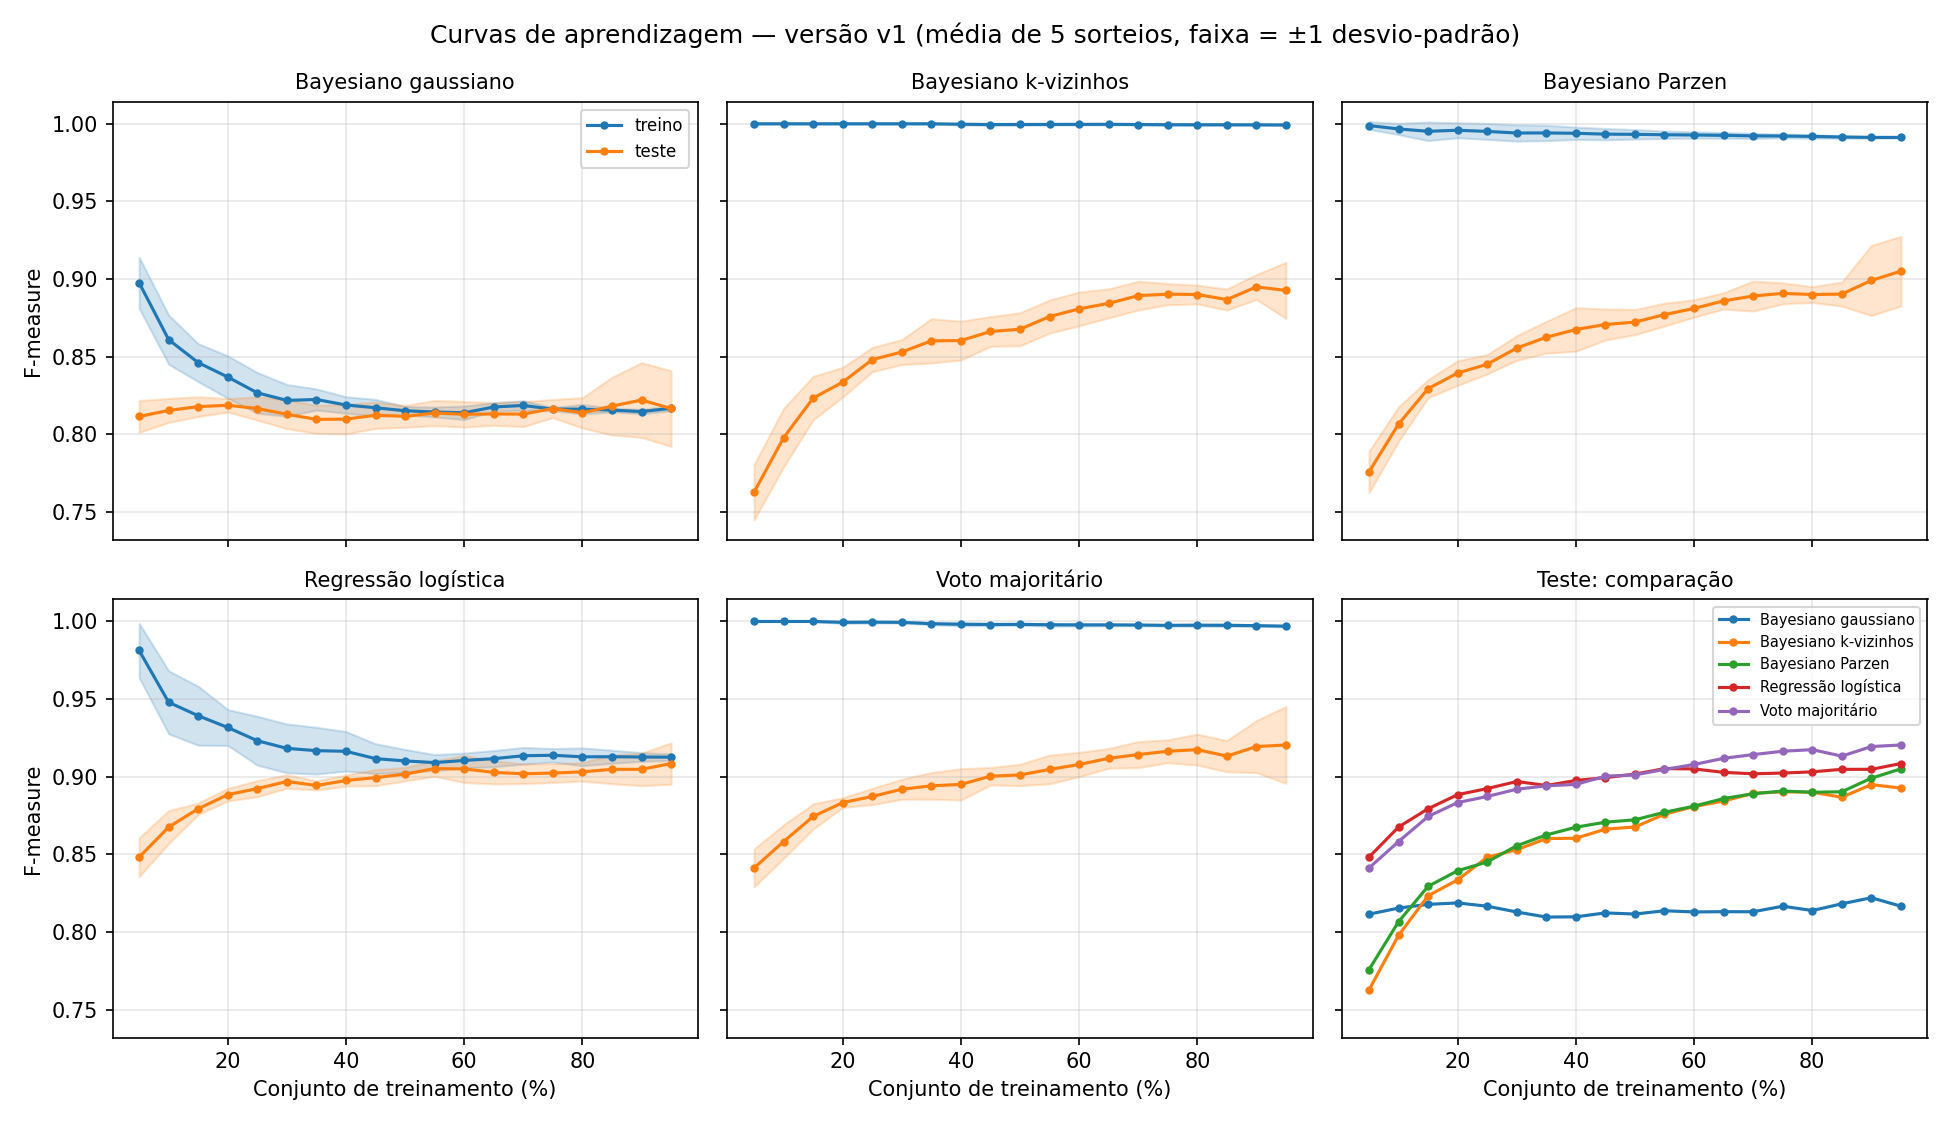

**v2**

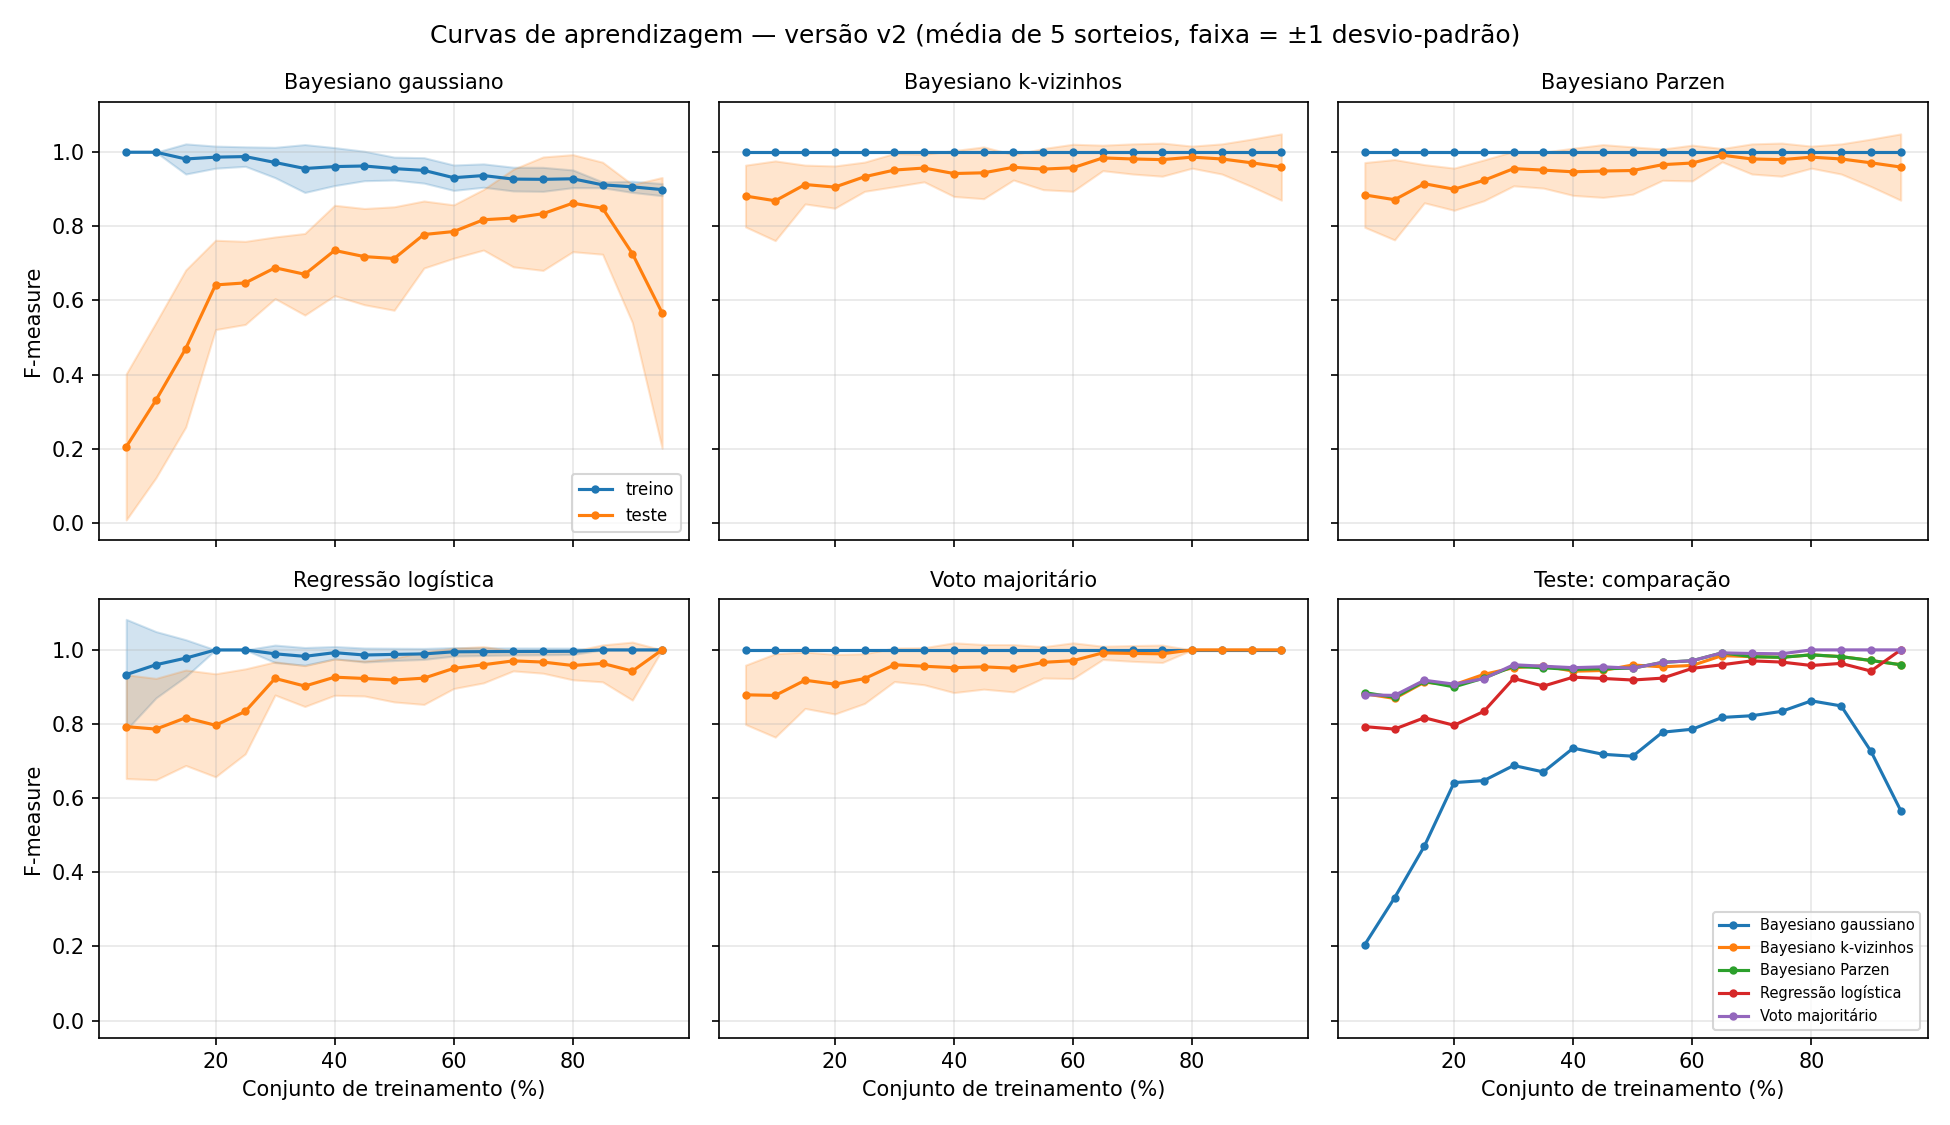

In [9]:
if RODAR_CURVAS:
    curva_aprendizagem.main()

for versao in comum.VERSOES:
    display(Markdown(f"**{versao}**"), Image(f"output/curva_{versao}.png", width=900))

## Comentários

- **v1.** O voto majoritário é o melhor em taxa de erro (6,4%) e F-measure (0,919). O Friedman rejeita H0 nas 4
  métricas e, pelo Nemenyi, todos os pares diferem em taxa de erro e F-measure. O gaussiano é o pior: cobertura alta
  (0,95) e precisão baixa (0,71), porque as variáveis (frequências cheias de zeros e muito assimétricas) estão longe
  da normal.
- **v2.** Todos acertam quase tudo (erro < 0,4%), pois os rótulos são uma partição do próprio X feita pelo double
  k-means. As diferenças entre k-vizinhos, Parzen, logística e voto são pequenas e várias não são significativas; o
  gaussiano é claramente pior, pois estima uma covariância 57 × 57 com ~30 exemplos da classe minoritária. Os IC são
  largos porque cada fold de teste tem só 3 ou 4 positivos.
- **Curvas.** Gaussiano (v1): treino e teste convergem para ~0,81, ou seja, erro de viés; mais dados não ajudam.
  k-vizinhos e Parzen: F-measure de treino ~1 (memorizam o treino) e de teste crescendo com o tamanho do treino,
  ou seja, variância alta que diminui com mais dados. Logística: a diferença entre treino e teste fecha a partir de
  ~50%. Na v2 as curvas de teste são ruidosas porque o conjunto de teste tem poucos positivos.